<hr>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

In [3]:
from pathlib import Path
import tarfile
import urllib.request

In [4]:
def load_day_data(): 
    tarball_path = Path("C://Users//zetap//Downloads//day.csv") 
    if not tarball_path.is_file(): 
        Path("C://Users//zetap//Downloads").mkdir(parents=True, exist_ok=True) 
        url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip" 
        urllib.request.urlretrieve(url, tarball_path) 
        with tarfile.open(tarball_path) as day_tarball: 
            day_tarball.extractall(path="C://Users//zetap//Downloads") 
    return pd.read_csv(Path("C://Users//zetap//Downloads//day.csv")) 
day = load_day_data()



In [5]:
print(day.head())


   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  


### Comment

The variables that may potentially used as predictors are instant,dteday,season,yr,mnth,holiday,weekday,workingday,wheathersit,temp,atemp,hum,windspeed,casual and registered. The target variable is cnt. We have a supervised machine learning, because the training set includes the labels. The task is to predict a target numeric value ("cnt"), given a set of features, so this problem is a regression problem. 

In [6]:
print(day.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None


In [7]:
day.describe().describe().T

,count,mean,std,min,25%,50%,75%,max
instant,8.0,392.270726,263.151211,1.000000,204.249359,366.000000,594.125000,731.0
season,8.0,93.450923,257.610688,1.000000,1.777702,2.748290,3.250000,731.0
yr,8.0,91.875128,258.245782,0.000000,0.375256,0.750342,1.000000,731.0
mnth,8.0,96.871469,256.251208,1.000000,3.862978,6.759918,10.500000,731.0
holiday,8.0,91.524485,258.387355,0.000000,0.000000,0.014364,0.375366,731.0
weekday,8.0,93.875256,257.444722,0.000000,1.753590,2.998632,5.250000,731.0
workingday,8.0,91.893653,258.238300,0.000000,0.348925,0.841997,1.000000,731.0
weathersit,8.0,92.617530,257.946614,0.544894,1.000000,1.197674,2.250000,731.0
temp,8.0,91.761258,258.291582,0.059130,0.298575,0.496859,0.706979,731.0
atemp,8.0,91.748807,258.296601,0.079070,0.294122,0.480543,0.666676,731.0


The variables that could be out of the dataset are instant, casual, registered and dteday. Instant is a record index, the dteday could be valuable if we didn't have yr and mnth. Casual gives a count of casual users, Registered gives a count of registered users. Cnt variable is total rental bikes including both casual and registered. If we use casual and registered the model won't learn anything from the other features because it is going to take information from these variables,this could be lead to data leakage. 

In [8]:
from pandas.plotting import scatter_matrix

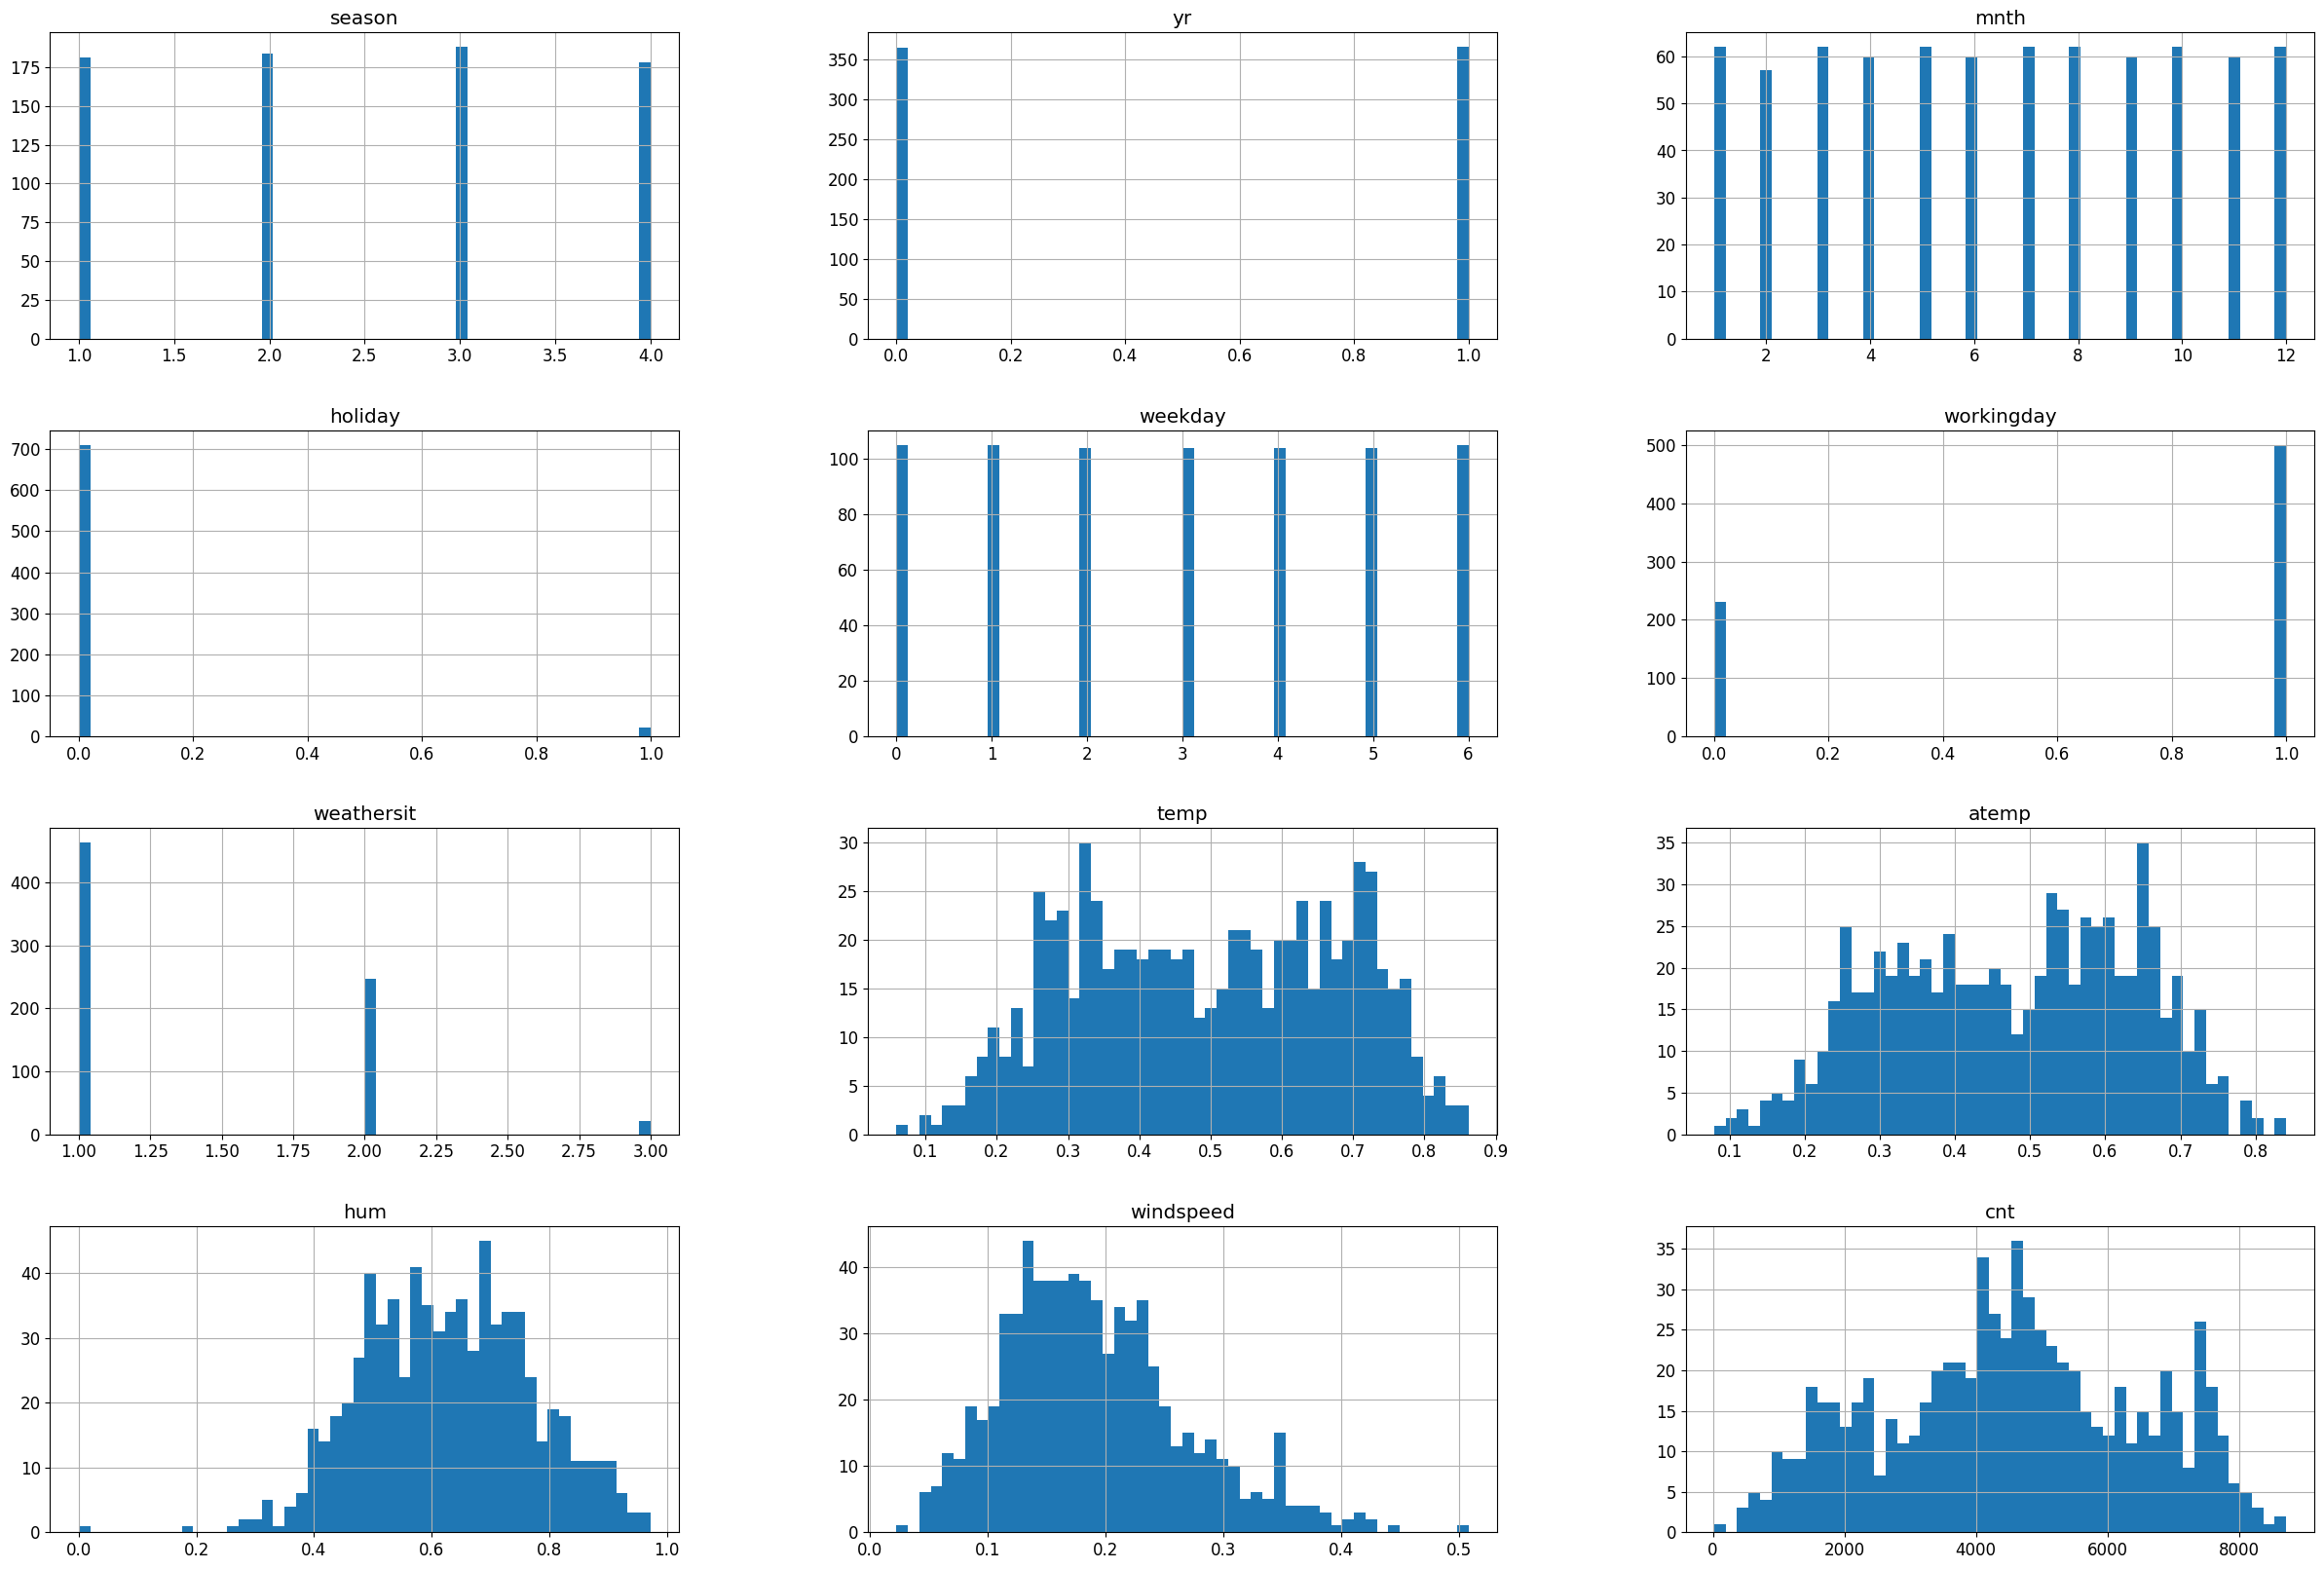

In [9]:
day.drop(columns=['instant', 'dteday', 'casual', 'registered'], inplace=True)
day.hist(bins=50, figsize=(30, 20), layout=(4, 3))
plt.show()


In [10]:
from scipy.stats import skew


In [11]:
day.skew()

season       -0.000384
yr           -0.002742
mnth         -0.008149
holiday       5.654224
weekday       0.002742
workingday   -0.793147
weathersit    0.957385
temp         -0.054521
atemp        -0.131088
hum          -0.069783
windspeed     0.677345
cnt          -0.047353
dtype: float64

In [12]:
from sklearn.preprocessing import FunctionTransformer

In [13]:
sqrt_transformer = FunctionTransformer(np.sqrt)
sqrt_windspeed = sqrt_transformer.transform(day[["windspeed"]])
sqrt_windspeed.skew()


windspeed    0.101294
dtype: float64

<Axes: title={'center': 'windspeed'}>

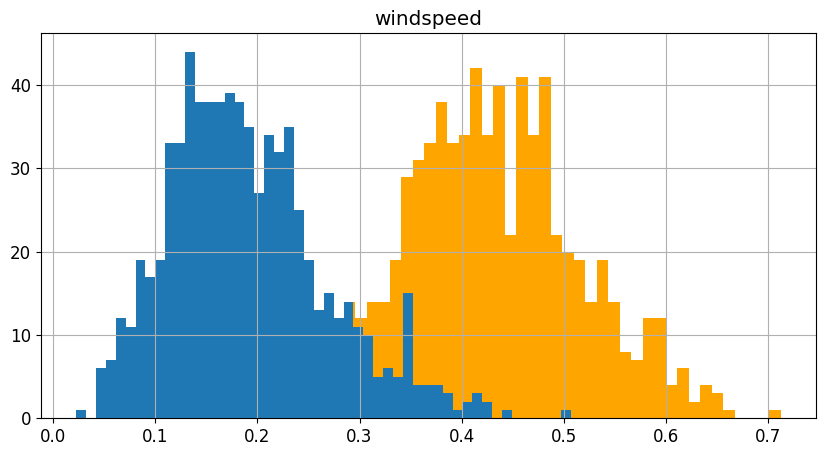

In [14]:
sqrt_windspeed.hist(bins=50, figsize=(10, 5),color='orange')
day["windspeed"].hist(bins=50, figsize=(10, 5))

### Comment
The attributes that seem to have a long tail are holiday,whethersit and windspeed. The other features have skew() under 0.5 .I proceed to transformation only for windspeed. Holiday has binary values and whethersit has nominal values. The long tail of holiday shows that the holidays in a year are less than the other day. Whethersit shows the number of winter, spring, summer and autumn days. 

In [15]:
corr_matrix=day.corr(method='pearson')
corr_matrix["cnt"].sort_values(ascending=False)

cnt           1.000000
atemp         0.631066
temp          0.627494
yr            0.566710
season        0.406100
mnth          0.279977
weekday       0.067443
workingday    0.061156
holiday      -0.068348
hum          -0.100659
windspeed    -0.234545
weathersit   -0.297391
Name: cnt, dtype: float64

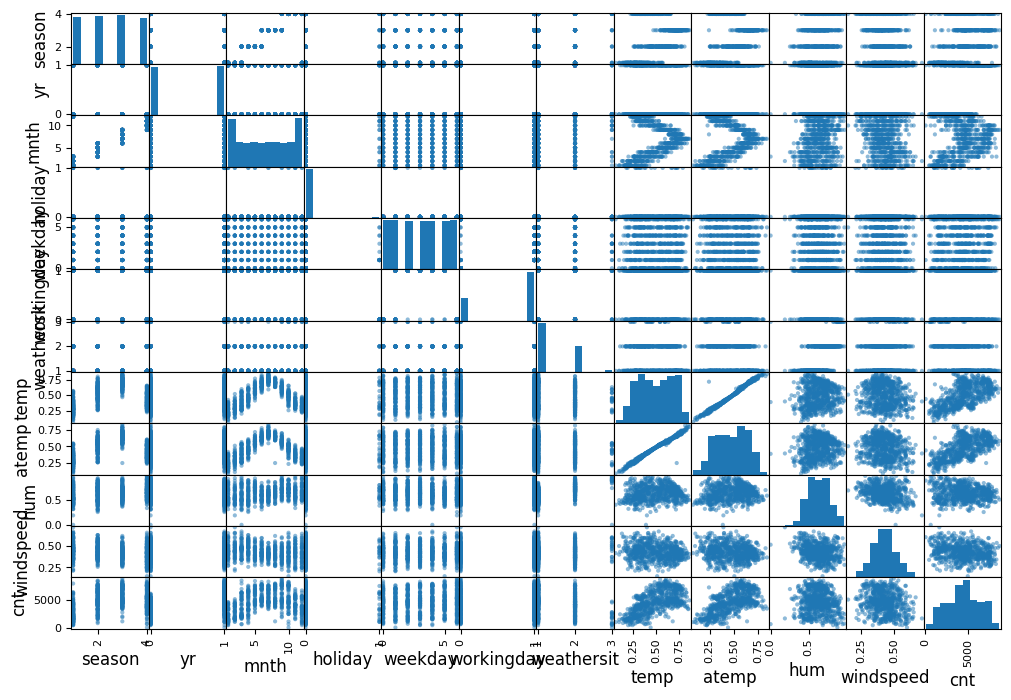

In [16]:
day['windspeed']=sqrt_windspeed
scatter_matrix(day, figsize=(12, 8))
plt.show()

### Comment

The correlation coefficient ranges from -1 to 1. When it is close to 1, it means that there is a strong prositive correlation. When the coefficient is close to -1, means that there is a strong negative correlation. Coefficients close to 0 mean that there is no linear correlation. We could say that atempt,temp,year,season and mnth have correlations >0.20 , weekday,  working day,holiday and hum are very close to zero and windspeed whethersit <-0,20 . According to the paterns that we observe we can take into consideration the attributes temp, atemp, hum and windspeed.  Year seems to have a correlation >0.50 but is a categorical variable such as year, season, mnth,holiday,weekday,workingday and weathersit. There are limitations for categorical variables. Categorical attributes are encoded with arbitrary numeric labels that carry no meaningful order or distance. The correlation coefficient only measures linear correlations . It may completely miss out on nonlinear relationships.


In [17]:
def shuffle_and_split_data(data, test_ratio):
    np.random.seed(42)
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [18]:
train_set,test_set=shuffle_and_split_data(day,0.2)
len(train_set),len(test_set)

(585, 146)

In [19]:
train_set_predictors=train_set.drop(columns=["cnt"])
train_set_target=train_set["cnt"]
test_set_predictors=test_set.drop(columns=["cnt"])
test_set_target=test_set["cnt"]

<Axes: >

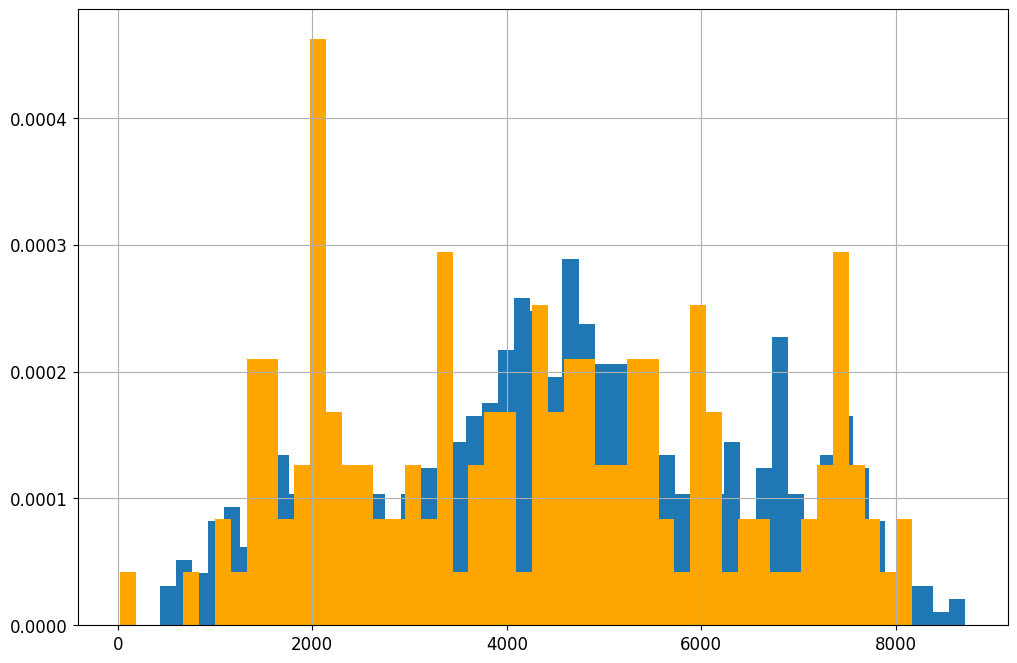

In [20]:
train_set_target.hist(bins=50,figsize=(12,8),density=True,label="train")
test_set_target.hist(bins=50,figsize=(12,8),density=True,label="test",color='orange')



### Comment

The subsets appear to represent similar target distrbutions. This is very important, because We want both sets be representative of the whole dataset. We want the performance measured on the test set be a reliable estimate of how a model will perform to unseen data. 

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.impute import SimpleImputer    
from sklearn.preprocessing import StandardScaler,OneHotEncoder


In [22]:
num_pipeline=make_pipeline(SimpleImputer(strategy="median"),StandardScaler())



In [23]:
preprocessing=make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
)

In [24]:
train_set_predictors_prepared= preprocessing.fit_transform(train_set_predictors)


In [25]:
preprocessing.get_feature_names_out()

array(['pipeline__season', 'pipeline__yr', 'pipeline__mnth',
       'pipeline__holiday', 'pipeline__weekday', 'pipeline__workingday',
       'pipeline__weathersit', 'pipeline__temp', 'pipeline__atemp',
       'pipeline__hum', 'pipeline__windspeed'], dtype=object)

In [26]:
df_train_set_predictors_prepared = pd.DataFrame(train_set_predictors_prepared,columns=preprocessing.get_feature_names_out(),index=train_set_predictors.index)

df_train_set_predictors_prepared

,pipeline__season,pipeline__yr,pipeline__mnth,pipeline__holiday,pipeline__weekday,pipeline__workingday,pipeline__weathersit,pipeline__temp,pipeline__atemp,pipeline__hum,pipeline__windspeed
135,-0.453001,-1.033024,-0.427877,-0.162221,-0.977751,0.701674,-0.731133,0.425866,0.445105,1.101331,-0.803403
682,1.362107,0.968032,1.324572,-0.162221,-0.483809,0.701674,1.088922,-0.865945,-0.962947,0.221497,1.774808
250,0.454553,-1.033024,0.740422,-0.162221,0.504074,0.701674,2.908978,0.737076,0.475145,2.168732,0.130667
336,1.362107,-1.033024,1.616646,-0.162221,1.491957,-1.425162,-0.731133,-1.109592,-1.041134,-0.130436,-1.329975
260,0.454553,-1.033024,0.740422,-0.162221,-1.471693,-1.425162,-0.731133,0.039703,0.073558,0.447319,-0.056035
...,...,...,...,...,...,...,...,...,...,...,...
71,-1.360555,-1.033024,-1.012027,-0.162221,-1.471693,-1.425162,-0.731133,-0.639681,-0.610660,-0.732426,1.045841
106,-0.453001,-1.033024,-0.719952,-0.162221,-1.471693,-1.425162,-0.731133,-0.240724,-0.204234,-1.068931,1.392094
270,1.362107,-1.033024,0.740422,-0.162221,0.010132,0.701674,1.088922,0.743072,0.597788,1.529515,-0.472641
435,-1.360555,0.968032,-1.012027,-0.162221,-1.471693,-1.425162,-0.731133,-0.764406,-0.737169,-1.087414,0.500056


In [27]:
from sklearn.linear_model import LinearRegression

In [28]:
lin_reg=make_pipeline(preprocessing,LinearRegression())
lin_reg.fit(train_set_predictors,train_set_target)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [29]:
train_set_predictions=lin_reg.predict(train_set_predictors)
train_set_predictions[:5]


array([3889.07369392, 4579.04657489, 3070.01379197, 3676.14882257,
       3628.7613914 ])

In [30]:
train_set_target[:5]

135    3958
682    4094
250    1842
336    3614
260    4274
Name: cnt, dtype: int64

### Comment

The parameters of the preprocessing transformations must be estimated using the training data rather than the the complete dataset.
We want to treat the test set as unseen data. If we include values ​​from the entire dataset, information leakage will occur and the model will appear highly accurate even though it might be not. 

In [31]:
test_set_predictors_prepared= preprocessing.fit_transform(test_set_predictors)

In [32]:
df_test_set_predictors_prepared = pd.DataFrame(test_set_predictors_prepared,
                                               columns=preprocessing.get_feature_names_out(),
                                               index=test_set_predictors.index
                                               )

df_test_set_predictors_prepared.describe().T

,count,mean,std,min,25%,50%,75%,max
pipeline__season,146.0,3.041707e-17,1.003442,-1.301269,-1.301269,0.449747,1.106378,1.325255
pipeline__yr,146.0,3.650048e-17,1.003442,-0.883452,-0.883452,-0.883452,1.131923,1.131923
pipeline__mnth,146.0,-9.125121e-17,1.003442,-1.620287,-1.055700,0.073474,0.920354,1.484941
pipeline__holiday,146.0,-4.258390e-17,1.003442,-0.207020,-0.207020,-0.207020,-0.207020,4.830459
pipeline__weekday,146.0,1.095014e-16,1.003442,-1.602496,-1.080254,-0.035770,1.008714,1.530956
pipeline__workingday,146.0,3.650048e-17,1.003442,-1.685854,-1.685854,0.593171,0.593171,0.593171
pipeline__weathersit,146.0,1.703356e-16,1.003442,-0.706380,-0.706380,-0.706380,1.203463,3.113306
pipeline__temp,146.0,2.311697e-16,1.003442,-2.010788,-0.842481,-0.140919,0.895220,1.905555
pipeline__atemp,146.0,-2.311697e-16,1.003442,-2.026645,-0.824386,-0.079384,0.888356,1.969096
pipeline__hum,146.0,-3.041707e-16,1.003442,-2.988042,-0.752347,-0.065114,0.673772,2.518587


In [33]:
lin_reg=make_pipeline(preprocessing,LinearRegression())
lin_reg.fit(test_set_predictors,test_set_target)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
test_set_predictions=lin_reg.predict(test_set_predictors)
test_set_predictions[:5]

array([6030.96210072, 1412.00382554, 2701.82368236, 4653.16058103,
       6613.56811251])

In [35]:
test_set_target[:5]

703    6606
33     1550
300    3747
456    6041
633    7538
Name: cnt, dtype: int64

In [36]:
from sklearn.metrics import r2_score


In [37]:
lim_r2=r2_score(test_set_predictions,test_set_target)
lim_r2

0.8086020660014175

In [38]:
from sklearn.metrics import mean_absolute_error

In [39]:
lim_mae=mean_absolute_error(test_set_predictions,test_set_target)
lim_mae

613.5754598353712

In [40]:
from sklearn.metrics import mean_absolute_percentage_error

In [41]:
lim_mape=mean_absolute_percentage_error(test_set_predictions,test_set_target)
lim_mape

0.17223699330048933

In [42]:
from sklearn.metrics import mean_squared_error

In [43]:
lim_mse=mean_squared_error(test_set_predictions,test_set_target)
lim_mse

648484.9219609298

In [44]:
from sklearn.metrics import root_mean_squared_error

In [45]:
lim_rmse=root_mean_squared_error(test_set_predictions,test_set_target)
lim_rmse

805.285615145912

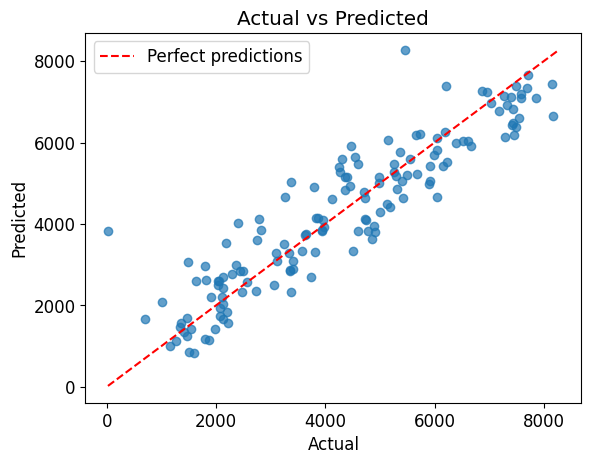

In [46]:
plt.scatter(test_set_target, test_set_predictions, alpha=0.7)
min_val = min(min(test_set_target), min(test_set_predictions))
max_val = max(max(test_set_target), max(test_set_predictions))

plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect predictions')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
plt.title("Actual vs Predicted")
plt.show()

### Comment

The most predicted values seem to be close to the real line, so the predictions are not so bad, but there are predictions that are further. With linear regression we found the linear relationships in the data, but it would be better if the model could also find the nonlinear relationships. In this case we could give a try with RandomForestRegressor. 

In [47]:
from sklearn.model_selection import cross_val_score 
from sklearn.model_selection import KFold

In [48]:
day_predictors = day.drop(columns=["cnt"])

In [49]:

lin_reg_r2 = cross_val_score(lin_reg, day_predictors, day["cnt"], scoring="r2", cv=KFold(10, shuffle=True, random_state=42))
print(lin_reg_r2.mean())
print(lin_reg_r2.std())

0.7770632310645289
0.07248256768155513


### Comment

The R^2 on the test set (close to 0,80) is close to the mean R^2 from 10-fold-cross-validation (0,777). We could say that the train/test split is representative of the whole dataset and the model does not suffer from overfitting.

<hr>